# p06_knowledge_graph — the procurement knowledge graph as Delta node and edge tables

Connects the structured procurement model to the outcome project's documents and risk scores in one typed graph:

%md-sandbox
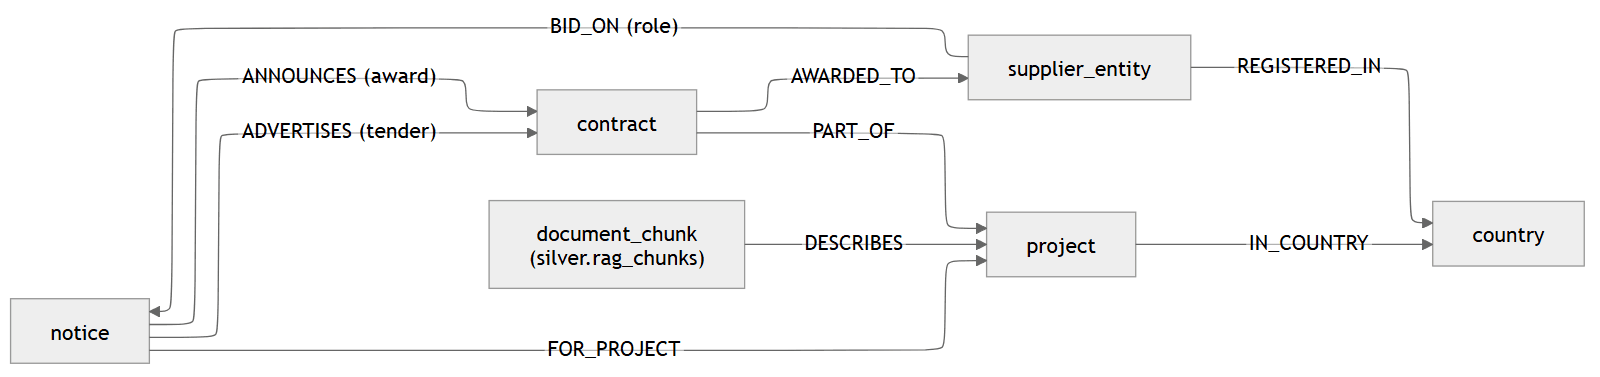

<details><summary>Diagram source (Mermaid)</summary>

<pre><code>---
config:
  layout: elk
  htmlLabels: false
  flowchart:
    htmlLabels: false
    wrappingWidth: 600
---
flowchart LR
    document_chunk["document_chunk&lt;br/&gt;(silver.rag_chunks)"]
    project["project"]
    country["country"]
    notice["notice"]
    contract["contract"]
    supplier_entity["supplier_entity"]
    project --&gt;|"IN_COUNTRY"| country
    supplier_entity --&gt;|"REGISTERED_IN"| country
    notice --&gt;|"FOR_PROJECT"| project
    document_chunk --&gt;|"DESCRIBES"| project
    notice --&gt;|"ADVERTISES (tender)"| contract
    notice --&gt;|"ANNOUNCES (award)"| contract
    contract --&gt;|"AWARDED_TO"| supplier_entity
    contract --&gt;|"PART_OF"| project
    supplier_entity --&gt;|"BID_ON (role)"| notice
</code></pre>

</details>

| Table | Grain | Key |
|---|---|---|
| `proc_gold.kg_nodes` | one node: project, contract, supplier_entity, country, notice, document_chunk | `node_id` (`<type>:<natural key>`) |
| `proc_gold.kg_edges` | one typed, directed relationship | `src_id, edge_type, dst_id` |

Every node id is `<type>:<key of the source table>`, so any node can be traced back to its silver row, and any document chunk to its passage in `silver.rag_chunks` (text and embedding stay there, joined by `chunk_id`).

## Why a graph in the lakehouse, not a separate graph database

- **One copy, one governance model.** Nodes and edges are Delta tables in Unity Catalog: the same permissions, lineage, time travel and audit as the silver tables they are built from. A separate graph store (Neo4j, Neptune) would need a sync pipeline, its own access control and its own backups, and would drift from the source.
- **The questions are batch and few-hop.** Analysts and the phase-2 agent ask 2-4 hop questions over a few million edges ("suppliers of high-risk projects and their other contracts"). Spark joins and GraphFrames motifs answer these in seconds; the low-latency deep traversals a graph database is built for are not needed.
- **It feeds models and retrieval directly.** Graph features (supplier history, co-bidding, project risk) join straight into the phase-2 training table, and the agent can expand a retrieved document chunk to its project, contracts and suppliers with SQL.
- **Upgrade path.** If interactive deep traversal becomes a requirement, the same node/edge tables can be exported to a graph database as a read replica, with Delta remaining the system of record.

## Key design decisions

| Decision | Rationale | Evidence |
|---|---|---|
| Supplier nodes are resolved `supplier_entities` from `p04`; notices and contracts keep their own grain | An id-level graph would split a firm's history | Ernst & Young India alone holds many ids |
| Document chunks from the outcome project's `silver.rag_chunks` (453 projects), linked by `project_id`, become nodes only for projects that appear in the procurement data | Only chunks connected to procurement records belong in the graph | The printed count shows the overlap |
| One node table: common columns (`node_id`, `node_type`, `name`) plus a `properties` map of strings; exact numeric types stay one join away in silver | Six node types must share one queryable table | A wide table would be mostly empty; one table per type would make generic traversals awkward |
| Demo questions written as DataFrame joins; one repeated as a GraphFrames motif when the library is available | Joins work on any runtime; the motif shows both styles give the same answer | The GraphFrames Python package ships with the ML runtime (checked in `p00`); loading of its JVM library is tested in the notebook |

Full reasoning: docs/decision_log.md

In [ ]:
%run ./proc_common

In [ ]:
import json

from pyspark.sql import DataFrame, Window

NODES, EDGES = f"{GOLD}.kg_nodes", f"{GOLD}.kg_edges"


def props(*cols: str):
    """String map of the given columns, dropping nulls."""
    pairs = [x for c in cols for x in (F.lit(c), F.col(c).cast("string"))]
    return F.map_filter(F.create_map(*pairs), lambda k, v: v.isNotNull())


def node(df: DataFrame, node_type: str, key: str, name, *prop_cols: str) -> DataFrame:
    return df.select(F.concat(F.lit(f"{node_type}:"), F.col(key)).alias("node_id"), F.lit(node_type).alias("node_type"),
                     name.alias("name"), props(*prop_cols).alias("properties"))


def edge(df: DataFrame, src_type: str, src_key: str, edge_type: str, dst_type: str, dst_key: str, *prop_cols: str) -> DataFrame:
    return (df.filter(F.col(src_key).isNotNull() & F.col(dst_key).isNotNull())
            .select(F.concat(F.lit(f"{src_type}:"), F.col(src_key)).alias("src_id"), F.lit(edge_type).alias("edge_type"),
                    F.concat(F.lit(f"{dst_type}:"), F.col(dst_key)).alias("dst_id"), props(*prop_cols).alias("properties")))

## 1. Nodes

**What:** one DataFrame per node type with its display name and key properties, unioned into `kg_nodes`.

**Why:** projects carry the outcome-model risk band, contracts their method/category/amount, supplier entities their activity, chunks their document type and section — the attributes the demo questions filter on.

In [ ]:
S = {t: spark.table(f"{SILVER}.{t}") for t in
     ["dim_project", "dim_country", "contracts", "supplier_entities", "supplier_entity_map", "contract_suppliers",
      "notices", "notice_bidders", "notice_contract_links"]}
# chunks of projects that appear in the procurement data; the others have no procurement node to describe
all_chunks = spark.table(RAG_CHUNKS).select("chunk_id", "project_id", "doc_id", "doc_type", "section", "chunk_index")
chunks = all_chunks.join(S["dim_project"].select("project_id"), "project_id", "left_semi")
print(f"document chunks: {chunks.count():,} of {all_chunks.count():,} kept "
      f"({chunks.select('project_id').distinct().count()} of {all_chunks.select('project_id').distinct().count()} "
      f"indexed projects have procurement data)")
contract_view = S["contracts"].withColumn("description_short", F.substring("contract_description", 1, 200))
nodes = (node(S["dim_project"], "project", "project_id", F.col("project_name"),
              "region", "major_sector", "approval_fy", "status", "outcome_risk_band", "outcome_risk_of_failure", "country_code")
         .unionByName(node(S["dim_country"], "country", "country_code", F.col("country_name"), "kind", "has_country_indicators"))
         .unionByName(node(contract_view, "contract", "contract_id", F.col("description_short"),
                           "procurement_method_name", "procurement_category_code", "review_type", "contract_amount_usd",
                           "signing_date", "is_joint_venture", "borrower_reference"))
         .unionByName(node(S["supplier_entities"], "supplier_entity", "supplier_entity_id", F.col("canonical_name"),
                           "country_code", "n_supplier_ids", "n_contracts", "value_won_usd", "n_times_not_awarded",
                           "is_individual_consultant"))
         .unionByName(node(S["notices"], "notice", "notice_id", F.col("bid_description"),
                           "notice_type", "notice_date", "procurement_method_name", "procurement_category_code",
                           "bid_reference", "submission_deadline"))
         .unionByName(node(chunks, "document_chunk", "chunk_id", F.concat_ws(" / ", "doc_type", "section"),
                           "project_id", "doc_id", "doc_type", "section", "chunk_index")))
n_nodes = publish_table(
    nodes, NODES,
    "Knowledge-graph nodes. Grain: one row per node. node_id = '<type>:<natural key>' (project_id, country_code, "
    "contract_id, supplier_entity_id, notice_id, chunk_id).",
    {"node_id": "PK. '<node_type>:<key in the source table>'",
     "node_type": "project, country, contract, supplier_entity, notice or document_chunk",
     "name": "Display name (project name, country, contract description, canonical supplier name, notice description, doc type / section)",
     "properties": "Type-specific attributes as strings"},
    primary_key=["node_id"])
display(spark.table(NODES).groupBy("node_type").count().orderBy(F.desc("count")))

document chunks: 43,340 of 50,000 kept (329 of 453 indexed projects have procurement data)


node_type       | count 
----------------+-------
notice          | 379820
supplier_entity | 316398
contract        | 282890
document_chunk  | 43340 
project         | 3768  
country         | 246   

## 2. Edges

**What:** the relationships of the diagram, each from its bridge or foreign key:

| Edge | From | Source |
|---|---|---|
| contract `PART_OF` project | contracts.project_id | FK |
| contract `AWARDED_TO` supplier_entity | contract_suppliers + supplier_entity_map | bridge (one edge per entity, joint ventures give several) |
| notice `ADVERTISES` contract | notice_contract_links, role tender | p05 (property: match tier) |
| notice `ANNOUNCES` contract | notice_contract_links, role award | p05 |
| notice `FOR_PROJECT` project | notices.project_id | FK |
| supplier_entity `BID_ON` notice | notice_bidders + supplier_entity_map | award notice HTML (property: role) |
| project `IN_COUNTRY` country | dim_project.country_code | FK |
| supplier_entity `REGISTERED_IN` country | supplier_entities.country_code | FK |
| document_chunk `DESCRIBES` project | silver.rag_chunks.project_id | outcome project |

**Why:** edges are derived only from keys that the earlier notebooks checked for orphans, so the graph inherits their integrity; edges whose end node is missing are counted below (expected 0).

In [ ]:
awarded_to = (S["contract_suppliers"].join(S["supplier_entity_map"], "supplier_id")
              .select("contract_id", "supplier_entity_id").distinct())
bid_on = (S["notice_bidders"].join(S["supplier_entity_map"], "supplier_id")
          .withColumn("_rank", F.when(F.col("role") == "awarded", 0).when(F.col("role") == "evaluated", 1).otherwise(2))
          .withColumn("_rn", F.row_number().over(Window.partitionBy("supplier_entity_id", "notice_id").orderBy("_rank")))
          .filter("_rn = 1").select("supplier_entity_id", "notice_id", "role"))
links = S["notice_contract_links"]
edges = (edge(S["contracts"], "contract", "contract_id", "PART_OF", "project", "project_id")
         .unionByName(edge(awarded_to, "contract", "contract_id", "AWARDED_TO", "supplier_entity", "supplier_entity_id"))
         .unionByName(edge(links.filter("link_role = 'tender'"), "notice", "notice_id", "ADVERTISES", "contract", "contract_id",
                           "match_tier", "notice_before_signing", "days_notice_to_signing"))
         .unionByName(edge(links.filter("link_role = 'award'"), "notice", "notice_id", "ANNOUNCES", "contract", "contract_id",
                           "match_tier", "supplier_confirmed"))
         .unionByName(edge(S["notices"], "notice", "notice_id", "FOR_PROJECT", "project", "project_id"))
         .unionByName(edge(bid_on, "supplier_entity", "supplier_entity_id", "BID_ON", "notice", "notice_id", "role"))
         .unionByName(edge(S["dim_project"], "project", "project_id", "IN_COUNTRY", "country", "country_code"))
         .unionByName(edge(S["supplier_entities"], "supplier_entity", "supplier_entity_id", "REGISTERED_IN", "country", "country_code"))
         .unionByName(edge(chunks, "document_chunk", "chunk_id", "DESCRIBES", "project", "project_id", "doc_type", "section")))
n_edges = publish_table(
    edges, EDGES,
    "Knowledge-graph edges. Grain: one row per (src_id, edge_type, dst_id); directed and typed.",
    {"src_id": "PK, FK kg_nodes", "edge_type": "PK. PART_OF, AWARDED_TO, ADVERTISES, ANNOUNCES, FOR_PROJECT, BID_ON, "
     "IN_COUNTRY, REGISTERED_IN, DESCRIBES", "dst_id": "PK, FK kg_nodes", "properties": "Edge attributes as strings"},
    primary_key=["src_id", "edge_type", "dst_id"])
add_foreign_key(EDGES, ["src_id"], NODES, ["node_id"])
add_foreign_key(EDGES, ["dst_id"], NODES, ["node_id"])
display(spark.table(EDGES).groupBy("edge_type").count().orderBy(F.desc("count")))

edge_type     | count 
--------------+-------
BID_ON        | 677556
FOR_PROJECT   | 379820
AWARDED_TO    | 295018
REGISTERED_IN | 290416
PART_OF       | 282890
ANNOUNCES     | 242812
ADVERTISES    | 64065 
DESCRIBES     | 43340 
IN_COUNTRY    | 3766  

## 3. Integrity

**What:** duplicate keys and dangling edges (an end that is not a node).

**Why:** a dangling edge would make traversals silently lose paths.

In [ ]:
N, E = spark.table(NODES), spark.table(EDGES)
display(dq_report([
    (NODES, "duplicate node_id", duplicate_keys(N, ["node_id"]), "== 0"),
    (EDGES, "duplicate edge key", duplicate_keys(E, ["src_id", "edge_type", "dst_id"]), "== 0"),
    (EDGES, "edges with unknown src_id", orphan_count(E, "src_id", N, "node_id"), "== 0"),
    (EDGES, "edges with unknown dst_id", orphan_count(E, "dst_id", N, "node_id"), "== 0"),
    (NODES, "nodes", N.count(), "info"), (EDGES, "edges", E.count(), "info"),
]))

table                             | check                     | value   | rule | status
----------------------------------+---------------------------+---------+------+-------
dbw_wb_outcome.proc_gold.kg_nodes | duplicate node_id         | 0       | == 0 | pass  
dbw_wb_outcome.proc_gold.kg_edges | duplicate edge key        | 0       | == 0 | pass  
dbw_wb_outcome.proc_gold.kg_edges | edges with unknown src_id | 0       | == 0 | pass  
dbw_wb_outcome.proc_gold.kg_edges | edges with unknown dst_id | 0       | == 0 | pass  
dbw_wb_outcome.proc_gold.kg_nodes | nodes                     | 1026462 | info | info  
dbw_wb_outcome.proc_gold.kg_edges | edges                     | 2279683 | info | info  

## 4. Question 1 — suppliers of civil works in high-risk projects, and their other contracts

**What:** path `supplier_entity <-AWARDED_TO- contract -PART_OF-> project` where the project is flagged **High** risk by the outcome model and the contract is civil works; then, for each such supplier, all its other contracts and projects.

**Why:** a supervisor of a risky project wants to know whether its contractors are stretched across many other contracts (capacity risk) or concentrated in other risky projects.

In [ ]:
def nodes_of(node_type: str) -> DataFrame:
    return N.filter(F.col("node_type") == node_type)


def edges_of(edge_type: str) -> DataFrame:
    return E.filter(F.col("edge_type") == edge_type).select("src_id", "dst_id")


high_risk = nodes_of("project").filter(F.col("properties")["outcome_risk_band"] == "High").select(F.col("node_id").alias("project"))
cw = nodes_of("contract").filter(F.col("properties")["procurement_category_code"] == "CW").select(F.col("node_id").alias("contract"))
part_of = edges_of("PART_OF").toDF("contract", "project")
awarded = edges_of("AWARDED_TO").toDF("contract", "supplier")
risky_cw = (cw.join(part_of, "contract").join(high_risk, "project").join(awarded, "contract"))
all_work = awarded.join(part_of, "contract").join(nodes_of("project").select(
    F.col("node_id").alias("project"), F.col("properties")["outcome_risk_band"].alias("band")), "project")
q1 = (risky_cw.groupBy("supplier").agg(F.countDistinct("contract").alias("high_risk_cw_contracts"),
                                       F.countDistinct("project").alias("high_risk_projects"))
      .join(all_work.groupBy("supplier").agg(F.countDistinct("contract").alias("all_contracts"),
                                             F.countDistinct("project").alias("all_projects"),
                                             F.countDistinct(F.when(F.col("band") == "High", F.col("project"))).alias("all_high_risk_projects")),
            "supplier")
      .join(nodes_of("supplier_entity").select(F.col("node_id").alias("supplier"), F.col("name").alias("supplier_name"),
                                                F.col("properties")["country_code"].alias("country")), "supplier")
      .withColumn("other_contracts", F.col("all_contracts") - F.col("high_risk_cw_contracts"))
      .orderBy(F.desc("high_risk_cw_contracts"), F.desc("other_contracts")))
print(f"suppliers with civil-works contracts in High-risk projects: {q1.count():,}")
display(q1.select("supplier_name", "country", "high_risk_cw_contracts", "high_risk_projects", "other_contracts",
                  "all_projects", "all_high_risk_projects").limit(10))

suppliers with civil-works contracts in High-risk projects: 4,372


supplier_name                       | country | high_risk_cw_contracts | high_risk_projects | other_contracts | all_projects | all_high_risk_projects
------------------------------------+---------+------------------------+--------------------+-----------------+--------------+-----------------------
HYDRONOMICS LIMITED                 | GH      | 17                     | 2                  | 1               | 3            | 2                     
SYNCLIME DRILLING COMPANY           | NG      | 12                     | 1                  | 1               | 1            | 1                     
CCB SAS                             | ML      | 11                     | 5                  | 4               | 5            | 5                     
AFRIC BUSINESS CENTRAL (ABC)        | BF      | 11                     | 1                  | 3               | 2            | 1                     
NOVMA ENTERPRISE                    | GH      | 11                     | 1                  | 1     

**What:** the same path as a GraphFrames motif, if the GraphFrames library loads on this cluster.

**Why:** shows the declarative graph-pattern style on the same tables; the count must equal the join version.

In [ ]:
try:
    from graphframes import GraphFrame
    # sub-graph with the two edge types of the pattern: a motif over all edges would expand every pair of
    # out-edges of every node (suppliers have thousands of BID_ON edges)
    sub_edges = E.filter(F.col("edge_type").isin("PART_OF", "AWARDED_TO"))
    g = GraphFrame(N.withColumnRenamed("node_id", "id"),
                   sub_edges.withColumnRenamed("src_id", "src").withColumnRenamed("dst_id", "dst"))
    motif = (g.find("(c)-[e1]->(p); (c)-[e2]->(s)")
             .filter("e1.edge_type = 'PART_OF' AND e2.edge_type = 'AWARDED_TO'")
             .filter("p.properties['outcome_risk_band'] = 'High' AND c.properties['procurement_category_code'] = 'CW'"))
    motif_suppliers = motif.select("s.id").distinct().count()
    print(f"GraphFrames motif: {motif_suppliers:,} suppliers (join version: {q1.count():,})")
    GRAPHFRAMES = True
except Exception as exc:  # the JVM package is not on every runtime
    print("GraphFrames not usable on this cluster:", type(exc).__name__, str(exc)[:200])
    GRAPHFRAMES = False

GraphFrames motif: 4,372 suppliers (join version: 4,372)


## 5. Question 2 — a new road tender in Kenya: similar past contracts and what the project documents say

**What:** past civil-works contracts in Kenya whose description mentions roads, with their project; then, for those projects that have documents in the outcome project's index, the chunks that mention procurement, contractors, bidding, delays or implementation arrangements most often (`contract <-` `-PART_OF-> project <-DESCRIBES- document_chunk`).

**Why:** this is the retrieval path the phase-2 assistant will use: structured precedent (amounts, methods, durations) plus the narrative evidence from the same projects. Keyword matching stands in for semantic search here (no model calls in this phase).

In [ ]:
COUNTRY, KEYWORD = "KE", "road"
EVIDENCE_TERMS = "procurement|contractor|bidding|delay|implementation arrangement"
in_country = edges_of("IN_COUNTRY").toDF("project", "country").filter(F.col("country") == f"country:{COUNTRY}")
road_contracts = (nodes_of("contract")
                  .filter((F.col("properties")["procurement_category_code"] == "CW") & F.lower("name").contains(KEYWORD))
                  .select(F.col("node_id").alias("contract"), F.col("name").alias("description"),
                          F.col("properties")["contract_amount_usd"].cast("double").alias("amount_usd"),
                          F.col("properties")["procurement_method_name"].alias("method"),
                          F.col("properties")["signing_date"].alias("signed"))
                  .join(part_of, "contract").join(in_country, "project"))
timeline = spark.table(f"{GOLD}.tender_timelines").select(F.concat(F.lit("contract:"), "contract_id").alias("contract"),
                                                           "days_notice_to_signing", "n_tender_notices")
precedents = road_contracts.join(timeline, "contract", "left")
print(f"past road works contracts in {COUNTRY}: {precedents.count():,}; timed: {precedents.filter('days_notice_to_signing IS NOT NULL').count():,}; "
      f"median days notice->signing: {precedents.agg(F.expr('percentile_approx(days_notice_to_signing, 0.5)')).first()[0]}")
display(precedents.orderBy(F.desc("amount_usd")).select("project", "description", "amount_usd", "method", "signed",
                                                         "days_notice_to_signing").limit(8))
describes = edges_of("DESCRIBES").toDF("chunk", "project")
evidence = (precedents.select("project").distinct().join(describes, "project")
            .join(spark.table(RAG_CHUNKS).select(F.concat(F.lit("document_chunk:"), "chunk_id").alias("chunk"),
                                                 "doc_type", "section", "chunk_text"), "chunk")
            .withColumn("keyword_hits", F.size(F.expr(f"regexp_extract_all(lower(chunk_text), '{EVIDENCE_TERMS}', 0)")))
            .filter("keyword_hits > 0")
            .withColumn("excerpt", F.substring("chunk_text", 1, 240)))
print(f"projects with documents: {evidence.select('project').distinct().count()} | matching chunks: {evidence.count():,}")
display(evidence.withColumn("rn", F.row_number().over(Window.partitionBy("project").orderBy(F.desc("keyword_hits"), "chunk")))
        .filter("rn <= 3").select("project", "doc_type", "section", "keyword_hits", "excerpt").limit(9))

past road works contracts in KE: 37; timed: 25; median days notice->signing: 110


project         | description                                                                                                                                                                                           | amount_usd   | method           | signed     | days_notice_to_signing
----------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------+------------------+------------+-----------------------
project:P161305 | UPGRADING OF KULAMAWE - MODOGASHE ROAD AND GARBATULA SPUR ROAD (128 Km) AND CIVIL WORKS ASSOCIATED WITH INSTALLING A FIBRE OPTIC CABLE ALONG THE KULAMAWE - MODOGASHE - SAMATAR ROAD SECTION (218 KM) | 146505312.33 | Request for Bids | 2022-04-15 | None                  
project:P161305 | UPGRADING OF ISIOLO-KULAMAWE (A10/B84) ROAD AND CIVIL WORKS ASSOCIATED WITH INSTALLING A FIBRE OPTIC CABLE ALONG THE R

projects with documents: 1 | matching chunks: 100


project         | doc_type                   | section                                                                                                                                               | keyword_hits | excerpt                                                                                                                                                                                                                                         
----------------+----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------+--------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
project:P161305 | Project Appraisal Document | IV. PROJECT APPRAISAL SUMMARY > B. Fiduciar

## 6. Question 3 — who keeps bidding against whom?

**What:** pairs of supplier entities named together in many award notices (`supplier -BID_ON-> notice <-BID_ON- supplier`), with how often each of them won.

**Why:** repeated co-bidding where the same firm always loses is a classic red flag for cover bidding or bid rotation. This is a screening signal for phase 2, not a finding: frequent co-bidding is also what a small, specialised market looks like.

In [ ]:
bids = (E.filter("edge_type = 'BID_ON'")
        .select(F.col("src_id").alias("supplier"), F.col("dst_id").alias("notice"), F.col("properties")["role"].alias("role")))
pairs = (bids.alias("a").join(bids.alias("b"), "notice")
         .filter(F.col("a.supplier") < F.col("b.supplier"))
         .groupBy(F.col("a.supplier").alias("supplier_a"), F.col("b.supplier").alias("supplier_b"))
         .agg(F.count("*").alias("shared_notices"),
              F.sum((F.col("a.role") == "awarded").cast("int")).alias("a_won"),
              F.sum((F.col("b.role") == "awarded").cast("int")).alias("b_won"))
         .filter("shared_notices >= 10"))
names = nodes_of("supplier_entity").select(F.col("node_id"), F.col("name"), F.col("properties")["country_code"].alias("country"))
q3 = (pairs.join(names.toDF("supplier_a", "name_a", "country_a"), "supplier_a")
      .join(names.toDF("supplier_b", "name_b", "country_b"), "supplier_b")
      .withColumn("one_side_never_wins", (F.col("a_won") == 0) | (F.col("b_won") == 0)))
print(f"supplier pairs named together in >= 10 award notices: {q3.count():,}; of which one side never won: "
      f"{q3.filter('one_side_never_wins').count():,}")
display(q3.orderBy(F.desc("shared_notices")).select("name_a", "name_b", "country_a", "shared_notices", "a_won", "b_won").limit(10))

supplier pairs named together in >= 10 award notices: 14,478; of which one side never won: 9,346


name_a                              | name_b                         | country_a | shared_notices | a_won | b_won
------------------------------------+--------------------------------+-----------+----------------+-------+------
SRS FERTILIZERS CORPORATION         | SHRI VEERAMATHIAMMAN AGENCIES  | IN        | 1158           | 769   | 70   
M.SUBRAMANIYAN,                     | SRS FERTILIZERS CORPORATION    | IN        | 1033           | 236   | 694  
M.SUBRAMANIYAN,                     | SHRI VEERAMATHIAMMAN AGENCIES  | IN        | 982            | 222   | 58   
SHANMUGAM AGRO SERVICE              | SHRI VEERAMATHIAMMAN AGENCIES  | IN        | 426            | 23    | 55   
SRS FERTILIZERS CORPORATION         | SHANMUGAM AGRO SERVICE         | IN        | 423            | 333   | 22   
SH. RAKESH KUMAR S/O SH. KEDAR NATH | RAJESH KUMAR S/O SH. DEEN DYAL | IN        | 368            | 96    | 124  
AMAN JARYAL                         | SAGAR SINGH                    | IN        | 335  

## 7. Question 4 — supplier entities winning across many borrower countries

**What:** `supplier_entity <-AWARDED_TO- contract -PART_OF-> project -IN_COUNTRY-> country`, counting distinct borrower countries per supplier entity.

**Why:** multi-country firms are where entity resolution matters most (one firm, many registrations) and where cross-country lessons (performance in one country) can inform another. The supplier's own registration country is shown for contrast.

In [ ]:
q4 = (awarded.join(part_of, "contract").join(edges_of("IN_COUNTRY").toDF("project", "country"), "project")
      .groupBy("supplier").agg(F.countDistinct("country").alias("borrower_countries"),
                               F.countDistinct("contract").alias("contracts"))
      .join(nodes_of("supplier_entity").select(F.col("node_id").alias("supplier"), F.col("name").alias("supplier_name"),
                                               F.col("properties")["country_code"].alias("registered_in"),
                                               F.col("properties")["n_supplier_ids"].alias("supplier_ids")), "supplier")
      .filter(~F.col("supplier_name").isin("INDIVIDUAL CONSULTANT")))
print(f"supplier entities with contracts in 10+ borrower countries: {q4.filter('borrower_countries >= 10').count():,}")
display(q4.orderBy(F.desc("borrower_countries"), F.desc("contracts")).limit(10))

supplier entities with contracts in 10+ borrower countries: 56


supplier                   | borrower_countries | contracts | supplier_name                                  | registered_in | supplier_ids
---------------------------+--------------------+-----------+------------------------------------------------+---------------+-------------
supplier_entity:SE-34990   | 64                 | 311       | UNITED NATIONS CHILDREN'S FUND (UNICEF)        | 99            | 1           
supplier_entity:SE-35295   | 62                 | 520       | UNITED NATIONS OFFICE PROJECT SERVICES (UNOPS) | 99            | 1           
supplier_entity:SE-10615   | 31                 | 62        | FOOD AND AGRICULTURE ORGANIZATION (FAO)        | 99            | 1           
supplier_entity:SE-34964   | 29                 | 56        | UNITED NATIONS DEVELOPMENT PROGRAMME (UNDP)    | 99            | 1           
supplier_entity:SE-36276   | 27                 | 66        | WORLD FOOD PROGRAMME (WFP)                     | 99            | 1           
supplier_entity:SE-3

## Run summary

**What:** node and edge counts by type and the headline answers.

**Why:** a job run shows them without opening the notebook.

In [ ]:
summary = {"nodes": n_nodes, "edges": n_edges,
           "nodes_by_type": {r["node_type"]: r["count"] for r in N.groupBy("node_type").count().collect()},
           "edges_by_type": {r["edge_type"]: r["count"] for r in E.groupBy("edge_type").count().collect()},
           "q1_suppliers": q1.count(), "q3_pairs": q3.count(), "graphframes": GRAPHFRAMES}
print(summary)
dbutils.notebook.exit(json.dumps(summary))

{"nodes": 1026462, "edges": 2279683, "nodes_by_type": {"notice": 379820, "supplier_entity": 316398, "contract": 282890, "document_chunk": 43340, "project": 3768, "country": 246}, "edges_by_type": {"FOR_PROJECT": 379820, "BID_ON": 677556, "AWARDED_TO": 295018, "ANNOUNCES": 242812, "REGISTERED_IN": 290416, "PART_OF": 282890, "ADVERTISES": 64065, "DESCRIBES": 43340, "IN_COUNTRY": 3766}, "q1_suppliers": 4372, "q3_pairs": 14478, "graphframes": true}